In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv('train(1).csv')

In [3]:
df.head()

,ID_code,target,var_0,var_1,var_2,var_3,var_4,var_5,var_6,var_7,...,var_190,var_191,var_192,var_193,var_194,var_195,var_196,var_197,var_198,var_199
0,train_0,0,8.9255,-6.7863,11.9081,5.0930,11.4607,-9.2834,5.1187,18.6266,...,4.4354,3.9642,3.1364,1.6910,18.5227,-2.3978,7.8784,8.5635,12.7803,-1.0914
1,train_1,0,11.5006,-4.1473,13.8588,5.3890,12.3622,7.0433,5.6208,16.5338,...,7.6421,7.7214,2.5837,10.9516,15.4305,2.0339,8.1267,8.7889,18.3560,1.9518
2,train_2,0,8.6093,-2.7457,12.0805,7.8928,10.5825,-9.0837,6.9427,14.6155,...,2.9057,9.7905,1.6704,1.6858,21.6042,3.1417,-6.5213,8.2675,14.7222,0.3965
3,train_3,0,11.0604,-2.1518,8.9522,7.1957,12.5846,-1.8361,5.8428,14.9250,...,4.4666,4.7433,0.7178,1.4214,23.0347,-1.2706,-2.9275,10.2922,17.9697,-8.9996
4,train_4,0,9.8369,-1.4834,12.8746,6.6375,12.2772,2.4486,5.9405,19.2514,...,-1.4905,9.5214,-0.1508,9.1942,13.2876,-1.5121,3.9267,9.5031,17.9974,-8.8104


In [4]:
df.shape

(200000, 202)

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200000 entries, 0 to 199999
Columns: 202 entries, ID_code to var_199
dtypes: float64(200), int64(1), object(1)
memory usage: 308.2+ MB


In [6]:
df.isnull().sum().sum()

np.int64(0)

In [7]:
df['target'].value_counts()

target
0    179902
1     20098
Name: count, dtype: int64

In [8]:
df['target'].value_counts(normalize=True) * 100

target
0    89.951
1    10.049
Name: proportion, dtype: float64

In [9]:
df.duplicated().sum()

np.int64(0)

In [10]:
df.nunique()

ID_code    200000
target          2
var_0       94672
var_1      108932
var_2       86555
            ...  
var_195     57870
var_196    125560
var_197     40537
var_198     94153
var_199    149430
Length: 202, dtype: int64

In [11]:
df.describe()

,target,var_0,var_1,var_2,var_3,var_4,var_5,var_6,var_7,var_8,...,var_190,var_191,var_192,var_193,var_194,var_195,var_196,var_197,var_198,var_199
count,200000.000000,200000.000000,200000.000000,200000.000000,200000.000000,200000.000000,200000.000000,200000.000000,200000.000000,200000.000000,...,200000.000000,200000.000000,200000.000000,200000.000000,200000.000000,200000.000000,200000.000000,200000.000000,200000.000000,200000.000000
mean,0.100490,10.679914,-1.627622,10.715192,6.796529,11.078333,-5.065317,5.408949,16.545850,0.284162,...,3.234440,7.438408,1.927839,3.331774,17.993784,-0.142088,2.303335,8.908158,15.870720,-3.326537
std,0.300653,3.040051,4.050044,2.640894,2.043319,1.623150,7.863267,0.866607,3.418076,3.332634,...,4.559922,3.023272,1.478423,3.992030,3.135162,1.429372,5.454369,0.921625,3.010945,10.438015
min,0.000000,0.408400,-15.043400,2.117100,-0.040200,5.074800,-32.562600,2.347300,5.349700,-10.505500,...,-14.093300,-2.691700,-3.814500,-11.783400,8.694400,-5.261000,-14.209600,5.960600,6.299300,-38.852800
25%,0.000000,8.453850,-4.740025,8.722475,5.254075,9.883175,-11.200350,4.767700,13.943800,-2.317800,...,-0.058825,5.157400,0.889775,0.584600,15.629800,-1.170700,-1.946925,8.252800,13.829700,-11.208475
50%,0.000000,10.524750,-1.608050,10.580000,6.825000,11.108250,-4.833150,5.385100,16.456800,0.393700,...,3.203600,7.347750,1.901300,3.396350,17.957950,-0.172700,2.408900,8.888200,15.934050,-2.819550
75%,0.000000,12.758200,1.358625,12.516700,8.324100,12.261125,0.924800,6.003000,19.102900,2.937900,...,6.406200,9.512525,2.949500,6.205800,20.396525,0.829600,6.556725,9.593300,18.064725,4.836800
max,1.000000,20.315000,10.376800,19.353000,13.188300,16.671400,17.251600,8.447700,27.691800,10.151300,...,18.440900,16.716500,8.402400,18.281800,27.928800,4.272900,18.321500,12.000400,26.079100,28.500700


In [12]:
df['ID_code'].head()

0    train_0
1    train_1
2    train_2
3    train_3
4    train_4
Name: ID_code, dtype: object

In [13]:
X = df.drop(['ID_code', 'target'], axis=1)
y = df['target']

In [14]:
print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (200000, 200)
Target shape: (200000,)


In [15]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

In [16]:
print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)
print("Training target:", y_train.shape)
print("Testing target:", y_test.shape)

Training features: (160000, 200)
Testing features: (40000, 200)
Training target: (160000,)
Testing target: (40000,)


In [17]:
print("Training target distribution:")
print(y_train.value_counts(normalize=True) * 100)

print("\nTesting target distribution:")
print(y_test.value_counts(normalize=True) * 100)

Training target distribution:
target
0    89.95125
1    10.04875
Name: proportion, dtype: float64

Testing target distribution:
target
0    89.95
1    10.05
Name: proportion, dtype: float64


In [18]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [19]:
from sklearn.linear_model import LogisticRegression
lr_model = LogisticRegression(max_iter=1000)

lr_model.fit(X_train_scaled, y_train)

,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,None
,solver,'lbfgs'
,max_iter,1000
,multi_class,'deprecated'


In [20]:
y_pred = lr_model.predict(X_test_scaled)

In [21]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix, classification_report

In [22]:
print("Logistic Regression Performance")

print("Accuracy:", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred))
print("Recall:", recall_score(y_test, y_pred))
print("F1 Score:", f1_score(y_test, y_pred))
print("ROC-AUC:", roc_auc_score(y_test, lr_model.predict_proba(X_test_scaled)[:, 1]))

Logistic Regression Performance
Accuracy: 0.9134
Precision: 0.682175622542595
Recall: 0.258955223880597
F1 Score: 0.3754056978002164
ROC-AUC: 0.8598618773835104


In [23]:
cm = confusion_matrix(y_test, y_pred)

print(cm)

[[35495   485]
 [ 2979  1041]]


In [24]:
from sklearn.tree import DecisionTreeClassifier

In [25]:
dt_model = DecisionTreeClassifier(random_state=42)

dt_model.fit(X_train, y_train)

,criterion,'gini'
,splitter,'best'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,None
,random_state,42
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,class_weight,None


In [26]:
y_pred_dt = dt_model.predict(X_test)

In [27]:
print("Decision Tree Performance")

print("Accuracy:", accuracy_score(y_test, y_pred_dt))
print("Precision:", precision_score(y_test, y_pred_dt))
print("Recall:", recall_score(y_test, y_pred_dt))
print("F1 Score:", f1_score(y_test, y_pred_dt))
print("ROC-AUC:", roc_auc_score(y_test, dt_model.predict_proba(X_test)[:, 1]))

Decision Tree Performance
Accuracy: 0.83555
Precision: 0.20489155514536225
Recall: 0.2208955223880597
F1 Score: 0.2125927699305722
ROC-AUC: 0.5625600457965868


In [28]:
from sklearn.ensemble import RandomForestClassifier

In [29]:
rf_model = RandomForestClassifier(
    n_estimators=100,
    max_depth=10,
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train, y_train)

,n_estimators,100
,criterion,'gini'
,max_depth,10
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,'sqrt'
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [30]:
y_pred_rf = rf_model.predict(X_test)

In [31]:
print("Random Forest Performance")

print("Accuracy:", accuracy_score(y_test, y_pred_rf))
print("Precision:", precision_score(y_test, y_pred_rf))
print("Recall:", recall_score(y_test, y_pred_rf))
print("F1 Score:", f1_score(y_test, y_pred_rf))
print("ROC-AUC:", roc_auc_score(y_test, rf_model.predict_proba(X_test)[:, 1]))

Random Forest Performance
Accuracy: 0.8995
Precision: 0.0
Recall: 0.0
F1 Score: 0.0
ROC-AUC: 0.8016103128050686


/opt/anaconda3/lib/python3.13/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])


In [32]:
pd.Series(y_pred_rf).value_counts()

0    40000
Name: count, dtype: int64

In [33]:
y_prob_rf = rf_model.predict_proba(X_test)[:, 1]

print("Minimum probability:", y_prob_rf.min())
print("Maximum probability:", y_prob_rf.max())
print("Average probability:", y_prob_rf.mean())

Minimum probability: 0.05430607441199367
Maximum probability: 0.48305408882111117
Average probability: 0.09890948150691371


In [34]:
y_pred_rf_new = (y_prob_rf >= 0.10).astype(int)

In [35]:
print("Accuracy:", accuracy_score(y_test, y_pred_rf_new))
print("Precision:", precision_score(y_test, y_pred_rf_new))
print("Recall:", recall_score(y_test, y_pred_rf_new))
print("F1 Score:", f1_score(y_test, y_pred_rf_new))
print("ROC-AUC:", roc_auc_score(y_test, y_prob_rf))

Accuracy: 0.668075
Precision: 0.2025959005333162
Recall: 0.7843283582089552
F1 Score: 0.32201399172751877
ROC-AUC: 0.8016103128050686


In [36]:
for threshold in [0.10, 0.15, 0.20, 0.25, 0.30]:

    y_temp = (y_prob_rf >= threshold).astype(int)

    print("\nThreshold:", threshold)
    print("Precision:", precision_score(y_test, y_temp))
    print("Recall:", recall_score(y_test, y_temp))
    print("F1 Score:", f1_score(y_test, y_temp))


Threshold: 0.1
Precision: 0.2025959005333162
Recall: 0.7843283582089552
F1 Score: 0.32201399172751877

Threshold: 0.15
Precision: 0.4244256348246675
Recall: 0.3492537313432836
F1 Score: 0.38318777292576417

Threshold: 0.2
Precision: 0.645367412140575
Recall: 0.10049751243781095
F1 Score: 0.17391304347826086

Threshold: 0.25
Precision: 0.8125
Recall: 0.019402985074626865
F1 Score: 0.037900874635568516

Threshold: 0.3
Precision: 0.8461538461538461
Recall: 0.002736318407960199
F1 Score: 0.005454996280684354


In [37]:
y_pred_rf_best = (y_prob_rf >= 0.15).astype(int)

In [38]:
print("Random Forest - Threshold 0.15")
print("Accuracy:", accuracy_score(y_test, y_pred_rf_best))
print("Precision:", precision_score(y_test, y_pred_rf_best))
print("Recall:", recall_score(y_test, y_pred_rf_best))
print("F1 Score:", f1_score(y_test, y_pred_rf_best))
print("ROC-AUC:", roc_auc_score(y_test, y_prob_rf))

Random Forest - Threshold 0.15
Accuracy: 0.887
Precision: 0.4244256348246675
Recall: 0.3492537313432836
F1 Score: 0.38318777292576417
ROC-AUC: 0.8016103128050686


In [39]:
import xgboost
print(xgboost.__version__)

3.4.1


In [40]:
%pip show xgboost

Name: xgboost
Version: 3.4.1
Summary: XGBoost Python Package
Home-page: 
Author: 
Author-email: Hyunsu Cho <chohyu01@cs.washington.edu>, Jiaming Yuan <jm.yuan@outlook.com>
License-Expression: Apache-2.0
Location: /opt/anaconda3/lib/python3.13/site-packages
Requires: numpy, scipy
Required-by: 
Note: you may need to restart the kernel to use updated packages.


In [41]:
from xgboost import XGBClassifier

In [42]:
xgb_model = XGBClassifier(
    n_estimators=100,
    max_depth=4,
    learning_rate=0.1,
    random_state=42,
    eval_metric='logloss',
    n_jobs=-1
)

xgb_model.fit(X_train, y_train)

,objective,'binary:logistic'
,base_score,None
,booster,None
,callbacks,None
,colsample_bylevel,None
,colsample_bynode,None
,colsample_bytree,None
,device,None
,early_stopping_rounds,None
,enable_categorical,True
,eval_metric,'logloss'


In [43]:
y_pred_xgb = xgb_model.predict(X_test)
y_prob_xgb = xgb_model.predict_proba(X_test)[:, 1]

print("XGBoost Results")
print("Accuracy:", accuracy_score(y_test, y_pred_xgb))
print("Precision:", precision_score(y_test, y_pred_xgb))
print("Recall:", recall_score(y_test, y_pred_xgb))
print("F1 Score:", f1_score(y_test, y_pred_xgb))
print("ROC-AUC:", roc_auc_score(y_test, y_prob_xgb))

XGBoost Results
Accuracy: 0.9034
Precision: 0.8861386138613861
Recall: 0.0445273631840796
F1 Score: 0.0847939365229749
ROC-AUC: 0.845252990882165


In [44]:
for threshold in [0.10, 0.15, 0.20, 0.25, 0.30]:
    y_temp = (y_prob_xgb >= threshold).astype(int)

    print("\nThreshold:", threshold)
    print("Precision:", precision_score(y_test, y_temp))
    print("Recall:", recall_score(y_test, y_temp))
    print("F1 Score:", f1_score(y_test, y_temp))


Threshold: 0.1
Precision: 0.24750728639361866
Recall: 0.8027363184079602
F1 Score: 0.37835619650603824

Threshold: 0.15
Precision: 0.3812145748987854
Recall: 0.5855721393034826
F1 Score: 0.46179499754781755

Threshold: 0.2
Precision: 0.500302480338778
Recall: 0.41144278606965173
F1 Score: 0.45154245154245154

Threshold: 0.25
Precision: 0.5929752066115702
Recall: 0.2855721393034826
F1 Score: 0.3854936198791135

Threshold: 0.3
Precision: 0.6840753424657534
Recall: 0.19875621890547263
F1 Score: 0.3080185042405551


In [45]:
y_pred_xgb_best = (y_prob_xgb >= 0.15).astype(int)

print("XGBoost - Threshold 0.15")
print("Accuracy:", accuracy_score(y_test, y_pred_xgb_best))
print("Precision:", precision_score(y_test, y_pred_xgb_best))
print("Recall:", recall_score(y_test, y_pred_xgb_best))
print("F1 Score:", f1_score(y_test, y_pred_xgb_best))
print("ROC-AUC:", roc_auc_score(y_test, y_prob_xgb))

XGBoost - Threshold 0.15
Accuracy: 0.862825
Precision: 0.3812145748987854
Recall: 0.5855721393034826
F1 Score: 0.46179499754781755
ROC-AUC: 0.845252990882165


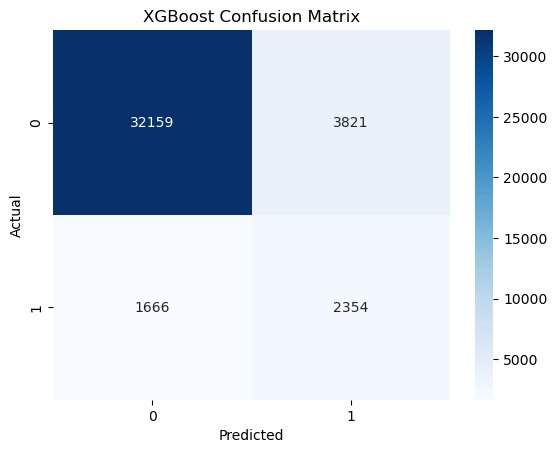

In [46]:
cm_xgb = confusion_matrix(y_test, y_pred_xgb_best)

sns.heatmap(cm_xgb, annot=True, fmt='d', cmap='Blues')
plt.title('XGBoost Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

In [47]:
print(classification_report(y_test, y_pred_xgb_best))

              precision    recall  f1-score   support

           0       0.95      0.89      0.92     35980
           1       0.38      0.59      0.46      4020

    accuracy                           0.86     40000
   macro avg       0.67      0.74      0.69     40000
weighted avg       0.89      0.86      0.88     40000



In [48]:
feature_importance = pd.DataFrame({
    'Feature': X.columns,
    'Importance': xgb_model.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by='Importance', ascending=False
)

print(feature_importance.head(10))

     Feature  Importance
81    var_81    0.028464
139  var_139    0.023849
12    var_12    0.018758
110  var_110    0.018313
109  var_109    0.016720
26    var_26    0.016496
146  var_146    0.016351
177  var_177    0.015726
133  var_133    0.014811
53    var_53    0.014486


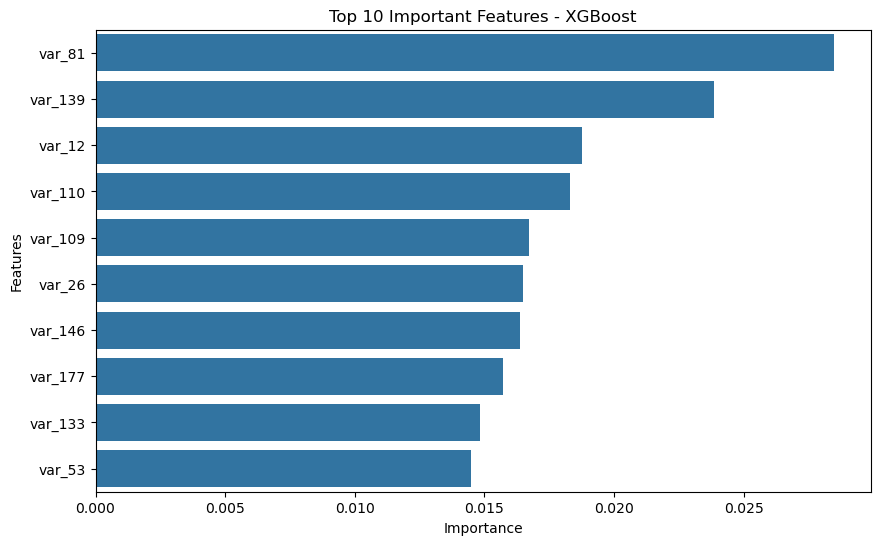

In [49]:
top_features = feature_importance.head(10)

plt.figure(figsize=(10, 6))
sns.barplot(data=top_features, x='Importance', y='Feature')

plt.title('Top 10 Important Features - XGBoost')
plt.xlabel('Importance')
plt.ylabel('Features')
plt.show()

## 1. Data Analysis Report

### Dataset Overview
The dataset contains 200,000 customer records and 202 columns, including 200 anonymized features, one customer ID column and one target column.

### Data Quality
- No missing values were found.
- No duplicate records were identified.
- The ID_code column contains unique customer identifiers and was excluded from model training.
- All 200 feature columns were retained for model development.

### Target Variable Analysis
The target variable contains two classes:
- Class 0: 179,902 records (89.95%), representing customers who will not make a future transaction.
- Class 1: 20,098 records (10.05%), representing customers who will make a future transaction.

### Key Observation
The dataset is imbalanced, as approximately 90% of records belong to class 0 and only 10% belong to class 1. Therefore, accuracy alone is not sufficient for evaluating model performance. Precision, recall, F1-score and ROC-AUC were also considered.

## 2. Model Comparison Report

Four machine learning algorithms were evaluated:

1. Logistic Regression
2. Decision Tree
3. Random Forest
4. XGBoost

### Performance Comparison

| Evaluation Metric | Logistic Regression | Decision Tree | Random Forest | XGBoost |
|---|---:|---:|---:|---:|
| Accuracy | 91.34% | 83.56% | 88.70% | 86.28% |
| Precision | 68.22% | 20.49% | 42.44% | 38.12% |
| Recall | 25.90% | 22.09% | 34.93% | 58.56% |
| F1-score | 37.54% | 21.26% | 38.32% | 46.18% |
| ROC-AUC | 85.99% | 56.26% | 80.16% | 84.53% |

### Model Evaluation

- **Logistic Regression:** Achieved the highest accuracy and ROC-AUC, but had relatively low recall.
- **Decision Tree:** Showed the weakest overall performance across the evaluated metrics.
- **Random Forest:** Improved its ability to identify transaction customers after adjusting the classification threshold to 0.15.
- **XGBoost:** Achieved the highest recall (58.56%) and F1-score (46.18%) among the evaluated models using an adjusted threshold of 0.15.

### Final Model Recommendation

XGBoost is the preferred candidate for further evaluation because identifying more potential transaction customers is the main objective of this project.

It achieved a recall of 58.56%, meaning it identified a larger proportion of actual transaction customers than the other evaluated models.

However, its precision of 38.12% indicates that some predicted transaction customers will not actually transact. The model should undergo further validation and threshold tuning before production deployment.

**Note:** The comparison uses default thresholds for Logistic Regression and Decision Tree, and adjusted thresholds for Random Forest and XGBoost. The adjusted thresholds were explored on the test set, so these results should be treated as exploratory rather than

## Conclusion

The project demonstrated how machine learning can be used to predict whether customers are likely to make future transactions.

The dataset's class imbalance was a major challenge, making it important to evaluate metrics beyond accuracy. Threshold adjustment improved the identification of positive transaction cases, particularly with XGBoost.

Overall, XGBoost emerged as the preferred candidate for further evaluation based on its recall and F1-score. Additional validation and threshold optimization would be required before deploying the model in a real banking environment.